# Perspective Transformation

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

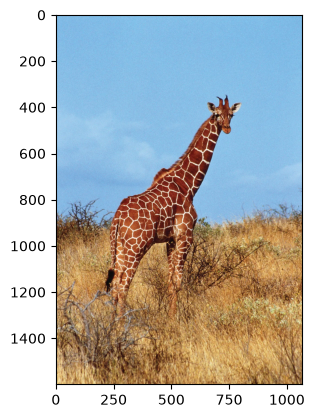

In [2]:
img = cv2.imread('./data/giraffe-Kenya.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)

In [3]:
img_rgb.shape

(1600, 1067, 3)

## Image with perspective transformation

In [29]:
def check_4_points(img, old_pts, new_pts):

    image = img.copy()

    for op, np in zip(old_pts, new_pts):
        cv2.circle(img=image, center=op, radius=15, color=(255,0,0), thickness=-1)
        cv2.circle(img=image, center=np, radius=15, color=(0,255,0), thickness=-1)

    return image

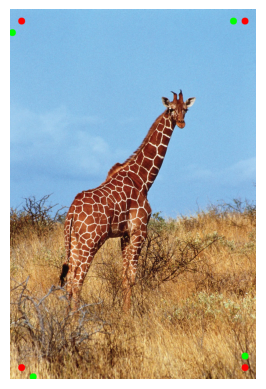

In [30]:
old_points = [(50,50), (1017,50), (50,1550), (1017,1550)]  # RED color
new_points = [(10,100), (967,50), (100,1590), (1017,1500)] # Green color

pst_transform = check_4_points(img_rgb, old_points, new_points)

plt.imshow(pst_transform)
plt.axis('off')
# plt.legend()
plt.show()

In [3]:
height, width, _ = img_rgb.shape

# input_points: where four points are located in the original image.
input_points = np.float32([[50, 50], [width-50,50], [50,height-50], [width-50,height-50]])

# output_points: where those same four points should end up in the transformed image.
output_points = np.float32([[10,100], [width-100,50], [100,height-10], [width-50,height-100]])

| Points | Input coordinate | Output coordinate |
|--------|------------------|-------------------|
|   P1   |      (50, 50)    |      (10, 100)    |
|   P2   |    (1017, 50)    |      (967, 50)    |
|   P3   |    (50, 1550)    |    (100, 1590)    |
|   P4   |  (1017, 1550)    |   (1017, 1500)    |


- P1 moves left and down.
- P2 moves left and stays higher.
- P3 moves right and down.
- P4 moves right and up.

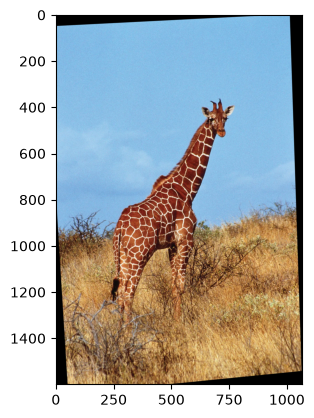

In [4]:
'''
Trasformation matrix for Perspective trasformation

3x3

a, b, c
d, e, f
g, h, 1

a,b,c is responsioble for horizontal scaling, rotation and tranlation
d,e,f is responsioble for vertical scaling, rotation and tranlation
g,h  : Perspective components that account for depth and skew

'''

# The transformation matrix calculated from the corresponding points.
M = cv2.getPerspectiveTransform(src=input_points, dst=output_points)

# Apply that matrix to produce the transformed image.
perspective_img = cv2.warpPerspective(src=img_rgb, M=M, dsize=(width, height))

# Show image
plt.imshow(perspective_img)

## Image with Affine transformation

In [33]:
def check_4_points(img, old_pts, new_pts):

    image = img.copy()

    for op, np in zip(old_pts, new_pts):
        cv2.circle(img=image, center=op, radius=15, color=(255,0,0), thickness=-1)
        cv2.circle(img=image, center=np, radius=15, color=(0,255,0), thickness=-1)

    return image

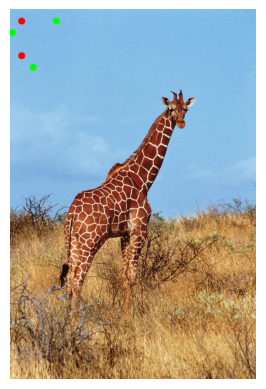

In [34]:
height, width, _ = img_rgb.shape

# old_points: where four points are located in the original image.
old_points = [[50,50], [200, 50], [50, 200]]

# new_points: where those same four points should end up in the transformed image.
new_points = [[10,100], [200, 50], [100, 250]]

af_transformation = check_4_points(img_rgb, old_points, new_points)

plt.imshow(af_transformation)
plt.axis('off')
plt.show()

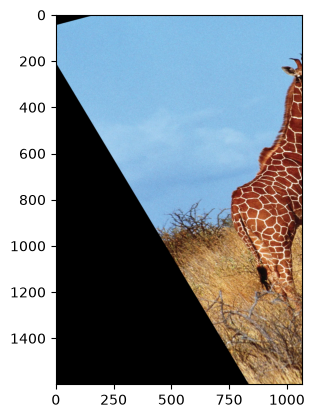

In [5]:
# input_points: where four points are located in the original image.
input_points = np.float32([[50,50], [200, 50], [50, 200]])

# output_points: where those same four points should end up in the transformed image.
output_points = np.float32([[10,100], [200, 50], [100, 250]])

'''
Trasformation matrix for Perspective trasformation

3x3

a, b, c
d, e, f
g, h, 1

a,b,c is responsioble for horizontal scaling, rotation and tranlation
d,e,f is responsioble for vertical scaling, rotation and tranlation
g,h  : Perspective components that account for depth and skew

'''

# The transformation matrix calculated from the corresponding points.
M = cv2.getAffineTransform(src=input_points, dst=output_points)

# Apply that matrix to produce the transformed image.
affine_img = cv2.warpAffine(src=img_rgb, M=M, dsize=(width, height))

# Show image
plt.imshow(affine_img)

## Image rotation

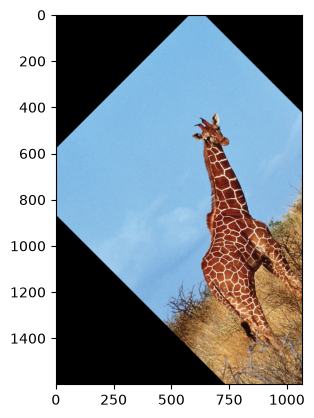

In [6]:
# scale = 1.0
angle = 45
center = (height // 2, width // 2)
scale = 1.0

M = cv2.getRotationMatrix2D(center, angle, scale)
'''
NOTE:

--> "angle = 45"
The image is rotated by 45 degrees.
- Positive angle: counterclockwise rotation in OpenCV's coordinate convention.
- Negative angle: clockwise rotation.

---------

--> "scale = 1.0"
This controls the size of the image during rotation.
| Scale |       Effect     |
|-------|------------------|
| 0.5   | Half the size    |
| 1.0	| Original size    |
| 2.0	| Twice the size   |


'''

rotated_img = cv2.warpAffine(img_rgb, M, (width, height))

plt.imshow(rotated_img)

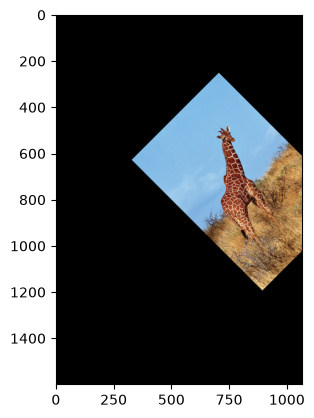

In [15]:
# scale = 0.5
angle = 45
center = (height // 2, width // 2)
scale = 0.5
M = cv2.getRotationMatrix2D(center, angle, scale)
rotated_img = cv2.warpAffine(img_rgb, M, (width, height))

plt.imshow(rotated_img)

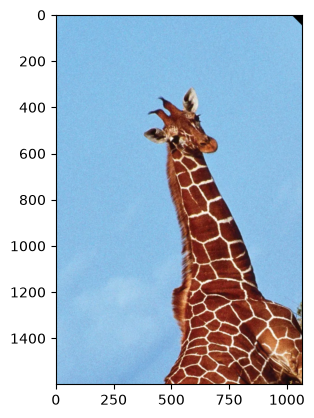

In [16]:
# scale = 2.0
angle = 45
center = (height // 2, width // 2)
scale = 2.0

M = cv2.getRotationMatrix2D(center, angle, scale)
rotated_img = cv2.warpAffine(img_rgb, M, (width, height))

plt.imshow(rotated_img)

## Image shearing

`shear_x = 0.5` and `shear_y = 0` mean that the image is sheared horizontally, so points farther down the image shift farther to the right.

which means:

$M = \begin{bmatrix} a & b & t_x \\ c & d & t_y \end{bmatrix} = \begin{bmatrix}1 & shear_x=0.5 & 0 \\ shear_y=0 & 1 & 0 \end{bmatrix}$

For image shearing, `b` $\ne$ `0` and `c` $\ne$ `0`, then `a` and `b` as same value. $t_x$ and $t_y$ must be zero.

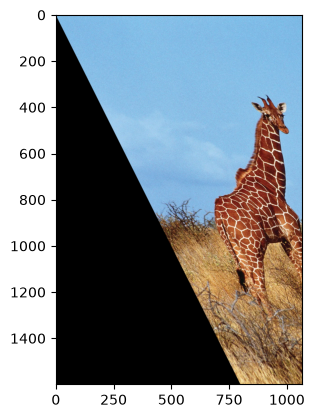

In [7]:
shear_x, shear_y = 0.5, 0

M = np.float32([[1,shear_x,0], 
                [shear_y,1,0]])

sheared_img = cv2.warpAffine(src=img_rgb, M=M, dsize=(width, height))

plt.imshow(sheared_img)

## Image translation

$t_x$ and $t_y$ move the image along X and Y axes without changing shape.

If we move the object in the image 50 pixel right and 100 pixel downard without shearing but scaling.

$M = \begin{bmatrix}
a & b & t_x \\
c & d & t_y
\end{bmatrix} = 
\begin{bmatrix}
1 & 0 & 200 \\
0 & 1 & 300
\end{bmatrix}$

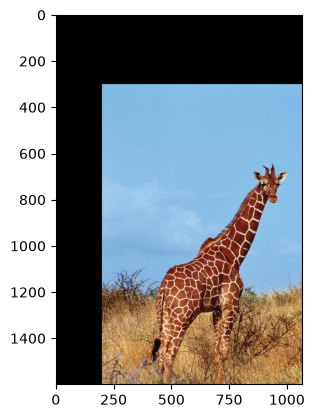

In [8]:
tx, ty = 200, 300

M = np.float32([[1,0,tx], 
                [0,1,ty]])

translated_img = cv2.warpAffine(img_rgb, M, (width, height))

plt.imshow(translated_img)

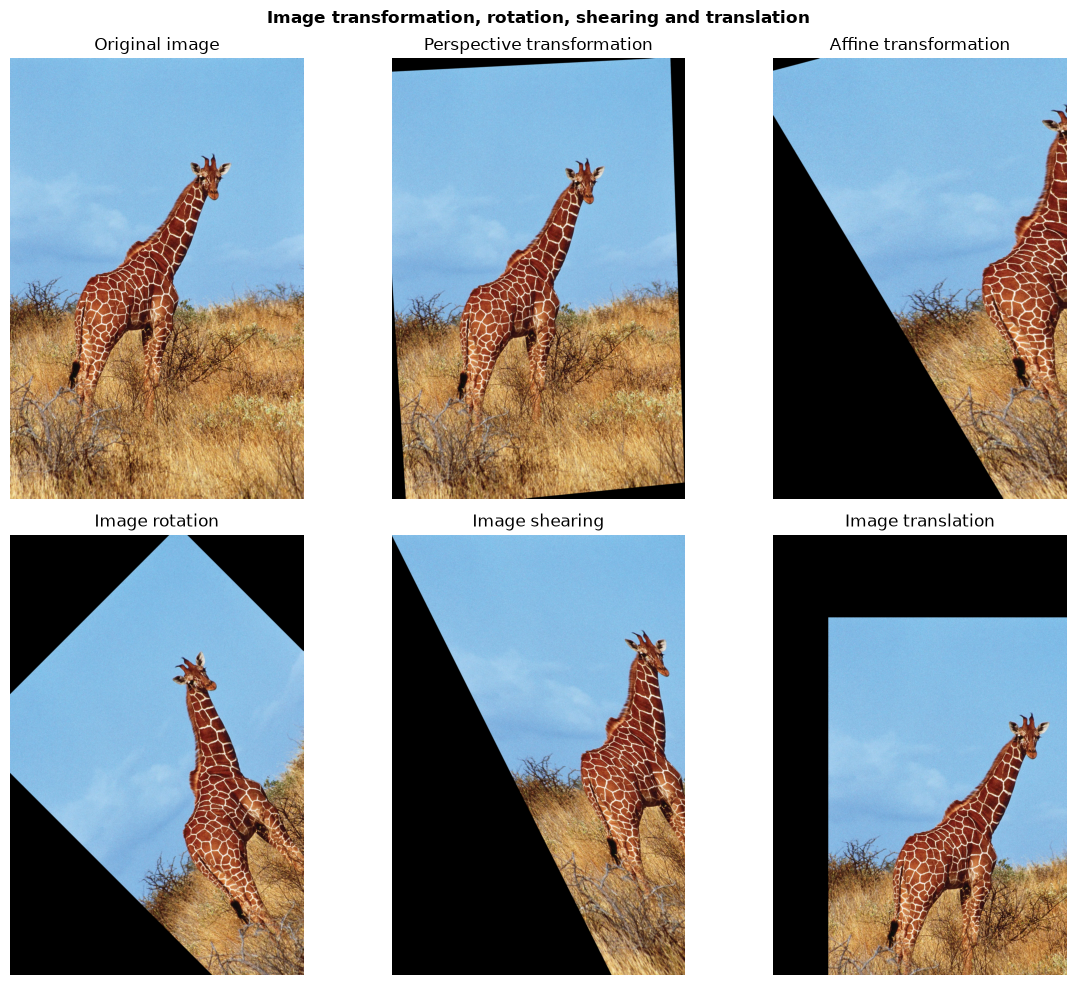

In [21]:
fig, axs = plt.subplots(2,3, figsize=(12,10))
methods = {"Original image": img_rgb, 
           "Perspective transformation": perspective_img, 
           "Affine transformation": affine_img, 
           "Image rotation": rotated_img, 
           "Image shearing": sheared_img, 
           "Image translation": translated_img}

for ax, (title, img) in zip(axs.flat, methods.items()):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle("Image transformation, rotation, shearing and translation", weight='bold', size=12)
plt.tight_layout()

# Save the entire figure
plt.savefig("image_transformations.jpg", dpi=300, bbox_inches="tight")


plt.show()